# Tabular Q-learning, scored against the exact answer

**Code:** [`algos/q_learning.py`](../algos/q_learning.py) · [`algos/sarsa.py`](../algos/sarsa.py) · [`experiments/sparse_vs_dense.py`](../experiments/sparse_vs_dense.py) · [`experiments/cliff_sarsa_vs_qlearning.py`](../experiments/cliff_sarsa_vs_qlearning.py) ·
**Papers:** Watkins 1989 ([PDF](../papers/tabular/watkins-1989-qlearning.pdf)), Sutton 1988 ([PDF](../papers/tabular/sutton-1988-td.pdf)), Rummery & Niranjan 1994 ([PDF](../papers/tabular/rummery-niranjan-1994-sarsa.pdf)), Ng et al. 1999 ([PDF](../papers/tabular/ng-1999-shaping.pdf)) ·
**Notes:** [`papers/tabular/notes.md`](../papers/tabular/notes.md)

What you will see:

1. The environment and its transition table, printed.
2. Q-learning on a dense reward, with every point on the curve an **exact** return, not a sampled average.
3. A one-line bug (`np.argmax` instead of random tie-breaking) that turns a learnable task into a score of 0.
4. The learned values against the true values, cell by cell.
5. Four reward functions on the same grid: dense learns fastest, potential-based shaping is *slower* than sparse on large grids, and a reward that looks almost correct is never solved.
6. SARSA against Q-learning on the cliff: one term of the target apart, two different policies.
7. Dyna-Q: a model learned from experience, replayed for planning.

Runs on CPU in about two minutes. Run from the repo root (`jupyter lab` at the top level) or with the repo installed (`pip install -e .`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from algos import q_learning
from algos.q_learning import steps_to_threshold, train
from diagnostics.plots import grid_figure
from diagnostics.render import compare_grids, policy_overlay
from envs.gridworld import GridWorld

GAMMA = 0.95
plt.rcParams["figure.dpi"] = 110

## 0. The problem and the data

**GridWorld.** An agent starts in one corner of an $n \times n$ grid and must reach the goal in the other.
Four actions: up, right, down, left. Walls block movement.

There is no dataset here. The agent generates its own data by acting.
Each step it produces one **transition**, and every transition comes from one table, `env.P`:

| column | meaning |
| --- | --- |
| `probability` | chance this outcome happens for this (state, action) |
| `next_state` | integer index of the cell the agent lands in |
| `reward` | reward for this transition; depends on `reward_mode` |
| `terminated` | `True` if the episode ends (the goal was entered) |

`step()` samples from this table and `envs/solvers.py` solves it exactly.
So the "true" Q function is computed from the same object the agent interacts with, and cannot disagree with it.

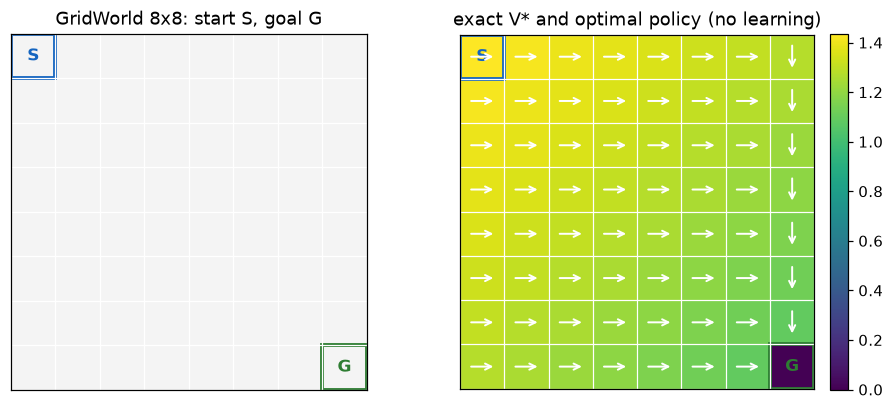


64 states, 4 actions, start=(0, 0), goal=(7, 7)

action  probability  next_state   reward  terminated
     0         1.00           0   -0.010       False
     1         1.00           1    0.090       False
     2         1.00           8    0.090       False
     3         1.00           0   -0.010       False


In [2]:
env = GridWorld(size=8, reward_mode="dense", gamma=GAMMA)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
grid_figure(env, axs[0], title="GridWorld 8x8: start S, goal G")
grid_figure(env, axs[1], values=env.true_v(GAMMA), policy=env.optimal_policy(GAMMA), title="exact V* and optimal policy (no learning)")
plt.show()
print(f"\n{env.n_states} states, {env.n_actions} actions, start={env.start}, goal={env.goal}\n")

start = env.index(env.start)
print(f"{'action':>6} {'probability':>12} {'next_state':>11} {'reward':>8} {'terminated':>11}")
for a in range(env.n_actions):
    for prob, s2, r, term in env.P[start][a]:
        print(f"{a:>6} {prob:>12.2f} {s2:>11} {r:>8.3f} {str(term):>11}")

## 1. The algorithm in one picture

Q-learning keeps a table `Q[state, action]` and nudges one entry per step towards a target.
The target uses `max` over the next state's actions, whatever the agent actually does next.
That `max` is what makes Q-learning **off-policy**.

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big(r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big)$$

In the code this is two lines: [`algos/q_learning.py:94-95`](../algos/q_learning.py).
The `0.0 if terminated` on line 94 is the terminal mask.

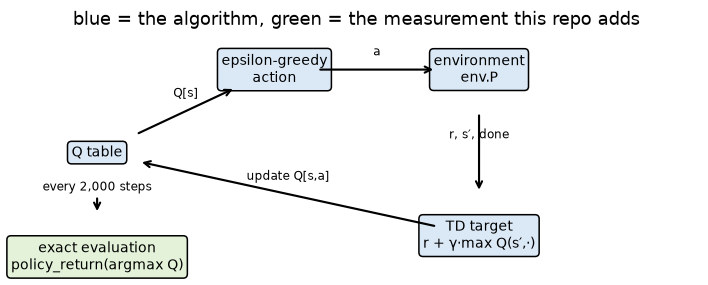

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.8)); ax.axis("off")
boxes = {"Q table": (0.12, 0.5), "epsilon-greedy\naction": (0.38, 0.85), "environment\nenv.P": (0.68, 0.85),
         "TD target\nr + γ·max Q(s′,·)": (0.68, 0.15), "exact evaluation\npolicy_return(argmax Q)": (0.12, 0.06)}
colour = {"exact evaluation\npolicy_return(argmax Q)": "#e3f2d9"}
for text, (x, y) in boxes.items():
    ax.text(x, y, text, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round", fc=colour.get(text, "#dbe9f6")))
def arrow(a, b, label=""):
    ax.annotate("", xy=boxes[b], xytext=boxes[a], arrowprops=dict(arrowstyle="->", lw=1.4, shrinkA=30, shrinkB=30))
    ax.text((boxes[a][0] + boxes[b][0]) / 2, (boxes[a][1] + boxes[b][1]) / 2 + 0.06, label, ha="center", fontsize=8)
arrow("Q table", "epsilon-greedy\naction", "Q[s]")
arrow("epsilon-greedy\naction", "environment\nenv.P", "a")
arrow("environment\nenv.P", "TD target\nr + γ·max Q(s′,·)", "r, s′, done")
arrow("TD target\nr + γ·max Q(s′,·)", "Q table", "update Q[s,a]")
arrow("Q table", "exact evaluation\npolicy_return(argmax Q)", "every 2,000 steps")
ax.set_title("blue = the algorithm, green = the measurement this repo adds"); plt.show()

## 2. Q-learning on a dense reward

`train` returns a learning curve. Each point is `policy_return(argmax Q)`: the exact expected return of the current greedy policy, from solving its Bellman equations.
There is no sampling noise in it. A wobble in this curve is the policy changing, not the measurement.

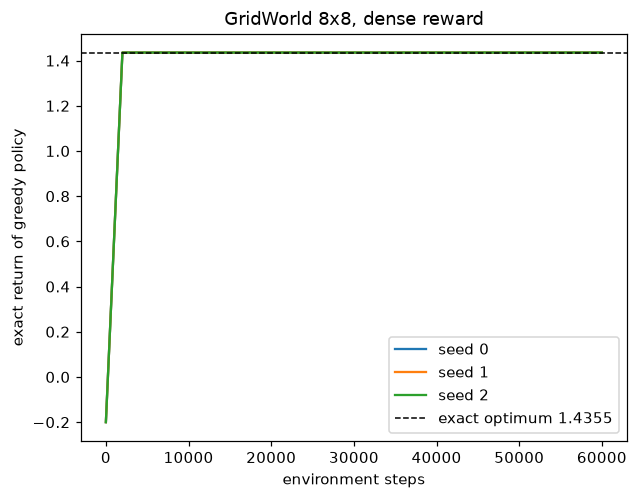

seed 0: steps to optimal = 2000
seed 1: steps to optimal = 2000
seed 2: steps to optimal = 2000


In [4]:
optimal = env.optimal_return(GAMMA)
curves = {seed: train(env, seed=seed)[1] for seed in range(3)}

for seed, curve in curves.items():
    steps, values = zip(*curve)
    plt.plot(steps, values, label=f"seed {seed}")
plt.axhline(optimal, color="k", ls="--", lw=1, label=f"exact optimum {optimal:.4f}")
plt.xlabel("environment steps"); plt.ylabel("exact return of greedy policy")
plt.title("GridWorld 8x8, dense reward"); plt.legend(); plt.show()

for seed, curve in curves.items():
    print(f"seed {seed}: steps to optimal = {steps_to_threshold(curve, optimal - 1e-6)}")

## 3. The bug that scores zero: `np.argmax` on a table of ties

A fresh Q table is all zeros, so every action ties.
`np.argmax` returns the **first** maximal entry, so a deterministic argmax picks action 0 in every unvisited state.
The agent then explores only through epsilon, 10% of the time.

The repo breaks ties at random ([`algos/q_learning.py:41-55`](../algos/q_learning.py)).
Below, the same training run on a **sparse** reward with that one function swapped for `np.argmax`.

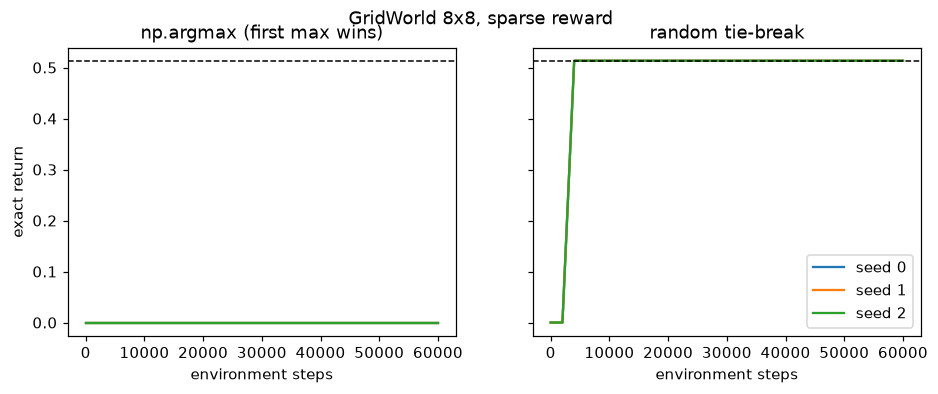

exact optimum: 0.5133
   np.argmax: final exact return per seed = [0.0, 0.0, 0.0]
 random ties: final exact return per seed = [0.5133, 0.5133, 0.5133]


In [5]:
sparse = GridWorld(size=8, reward_mode="sparse", gamma=GAMMA)
sparse_optimal = sparse.optimal_return(GAMMA)

def run(tie_break):
    original = q_learning.argmax_random_ties
    q_learning.argmax_random_ties = tie_break
    try:
        return [train(sparse, seed=seed)[1] for seed in range(3)]
    finally:
        q_learning.argmax_random_ties = original

fixed = run(q_learning.argmax_random_ties)
broken = run(lambda values, rng: int(np.argmax(values)))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, runs, title in ((axs[0], broken, "np.argmax (first max wins)"), (axs[1], fixed, "random tie-break")):
    for seed, curve in enumerate(runs):
        steps, values = zip(*curve)
        ax.plot(steps, values, label=f"seed {seed}")
    ax.axhline(sparse_optimal, color="k", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("environment steps")
axs[0].set_ylabel("exact return"); axs[1].legend(); plt.suptitle("GridWorld 8x8, sparse reward"); plt.show()

print(f"exact optimum: {sparse_optimal:.4f}")
for name, runs in (("np.argmax", broken), ("random ties", fixed)):
    print(f"{name:>12}: final exact return per seed = {[round(c[-1][1], 4) for c in runs]}")

Read the two panels together.
The tie-break is one of two reasons sparse Q-learning struggles; the other is that the goal is rarely reached by chance.
Only the second reason is a real property of the problem.

## 4. Learned values against true values

A plausible-looking curve does not mean the Q table is right.
`env.true_v` is the exact optimal value of every cell. `compare_grids` prints learned, true, and their difference.
A systematic error (same sign everywhere, growing towards the goal) is a bug. A speckled one is too little data.

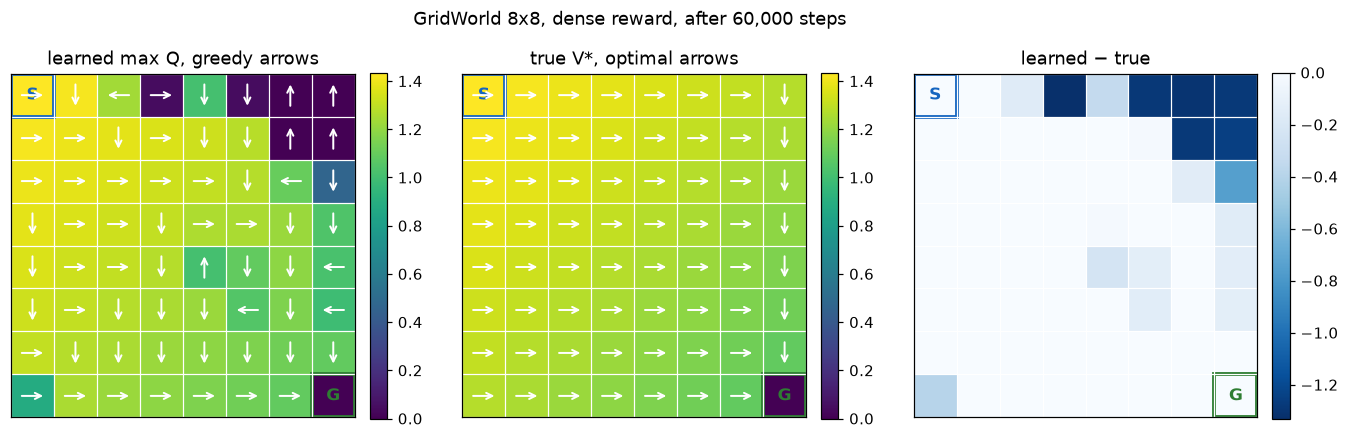

learned (gamma=0.95)   [+0 .. +1.44]
    1.44    1.42    1.24    0.05    1.01    0.05    0.00    0.00
    1.42    1.40    1.37    1.35    1.33    1.28    0.00    0.00
    1.40    1.37    1.35    1.33    1.30    1.28    1.10    0.47
    1.37    1.35    1.33    1.30    1.26    1.25    1.22    1.04
    1.35    1.33    1.30    1.28    1.01    1.09    1.19    1.02
    1.33    1.30    1.28    1.25    1.22    1.05    1.16    0.99
    1.30    1.28    1.25    1.22    1.19    1.16    1.13    1.09
    0.88    1.25    1.22    1.19    1.16    1.13    1.09    0.00

exact (gamma=0.95)   [+0 .. +1.44]
    1.44    1.42    1.40    1.37    1.35    1.33    1.30    1.28
    1.42    1.40    1.37    1.35    1.33    1.30    1.28    1.25
    1.40    1.37    1.35    1.33    1.30    1.28    1.25    1.22
    1.37    1.35    1.33    1.30    1.28    1.25    1.22    1.19
    1.35    1.33    1.30    1.28    1.25    1.22    1.19    1.16
    1.33    1.30    1.28    1.25    1.22    1.19    1.16    1.13
    1.30    1.28 

In [6]:
Q, _ = train(env, seed=0)
learned, truth = Q.max(axis=1), env.true_v(GAMMA)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
grid_figure(env, axs[0], values=learned, policy=Q, title="learned max Q, greedy arrows")
grid_figure(env, axs[1], values=truth, policy=env.optimal_policy(GAMMA), title="true V*, optimal arrows")
grid_figure(env, axs[2], values=learned - truth, title="learned − true", cmap="Blues_r")
plt.suptitle("GridWorld 8x8, dense reward, after 60,000 steps"); plt.show()
print(compare_grids(env, learned, truth, gamma_label=f"(gamma={GAMMA})"))
print()
print(policy_overlay(env, Q, "learned Q with greedy arrows"))

Every error has the same sign, and notebook 00 calls that the signature of a bug. Here it is not one.
The errors sit in cells the greedy path never visits (the top right, and one cell bottom left), where the table still holds its starting value of 0.
They are all negative only because 0 is below every true value.
So "one sign" needs a second check before you call it a bug: **where** the errors are.
The policy is optimal (section 2) while part of the table is wrong, because Q-learning only has to get the values right along the path it takes.

## 5. Four reward functions, one task

Same grid, four `reward_mode`s ([`envs/gridworld.py:182-209`](../envs/gridworld.py)):

| mode | reward | same optimal policy as sparse? |
| --- | --- | --- |
| `sparse` | +1 for entering the goal, nothing else | — |
| `dense` | progress towards the goal, minus a step cost | yes here, not in general |
| `shaped` | sparse + $\gamma\Phi(s') - \Phi(s)$, with $\Phi(\text{goal}) = 0$ | yes, provably (Ng et al. 1999) |
| `misspecified` | sparse + bonus for progress, **no penalty for going back** | no |

Every agent is **scored on the sparse task**, whatever it trained on.
Scoring a shaped agent by its own shaped reward measures the size of its bonus, not whether it solved anything.

The cell below runs a smaller version of `experiments/sparse_vs_dense.py`: three grid sizes, three seeds, 120,000 steps each.

In [7]:
from envs.gridworld import REWARD_MODES

SIZES, SEEDS = (6, 10, 14), (0, 1, 2)
table = {}
for size in SIZES:
    scorer = GridWorld(size=size, reward_mode="sparse", gamma=GAMMA, max_steps=300)
    target = 0.95 * scorer.optimal_return(GAMMA)
    for mode in REWARD_MODES:
        hits = []
        for seed in SEEDS:
            learner = GridWorld(size=size, reward_mode=mode, gamma=GAMMA, max_steps=300)
            _, curve = train(learner, n_steps=120_000, eval_every=5_000, eval_env=scorer, seed=seed)
            hits.append(steps_to_threshold(curve, target))
        table[size, mode] = hits

print("steps to reach 95% of the sparse optimum (median of seeds that got there; 'never' = fewer than 2)\n")
print(f"{'grid':>6} " + "".join(f"{m:>14}" for m in REWARD_MODES))
for size in SIZES:
    cells = []
    for mode in REWARD_MODES:
        reached = [h for h in table[size, mode] if h is not None]
        cells.append(f"{int(np.median(reached)):,}" if len(reached) >= 2 else "never")
    print(f"{f'{size}x{size}':>6} " + "".join(f"{c:>14}" for c in cells))

steps to reach 95% of the sparse optimum (median of seeds that got there; 'never' = fewer than 2)

  grid         sparse         dense        shaped  misspecified
   6x6          5,000         5,000         5,000         never
 10x10         10,000         5,000        55,000         never
 14x14         35,000         5,000        50,000         never


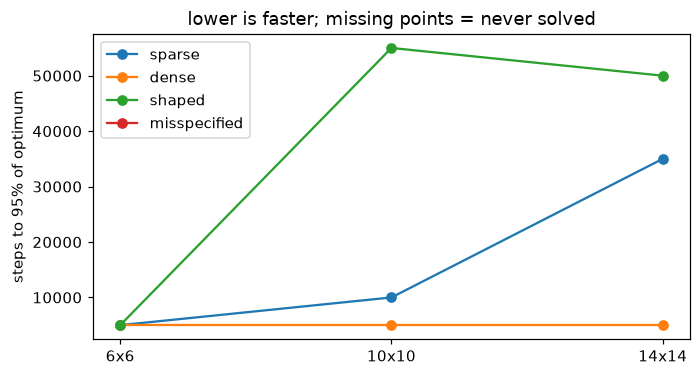

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for mode in REWARD_MODES:
    ys = []
    for size in SIZES:
        reached = [h for h in table[size, mode] if h is not None]
        ys.append(np.median(reached) if len(reached) >= 2 else np.nan)
    ax.plot([f"{s}x{s}" for s in SIZES], ys, marker="o", label=mode)
ax.set_ylabel("steps to 95% of optimum"); ax.set_title("lower is faster; missing points = never solved")
ax.legend(); plt.show()

**Why shaping can be slower, though it cannot change the optimal policy.**
Shaping adds $-\Phi(s)$ to every value.
But the margin between "solve the task" and "stand still collecting the shaping term" stays exactly the sparse return.
So on a large grid, every TD update must resolve a small difference that sits on a large baseline.
The full derivation is in `shaping_margin` in [`experiments/sparse_vs_dense.py`](../experiments/sparse_vs_dense.py).

**The misspecified reward is never solved.** The agent is not broken. Stepping towards the goal and back pays the bonus forever, and that is worth more than finishing.

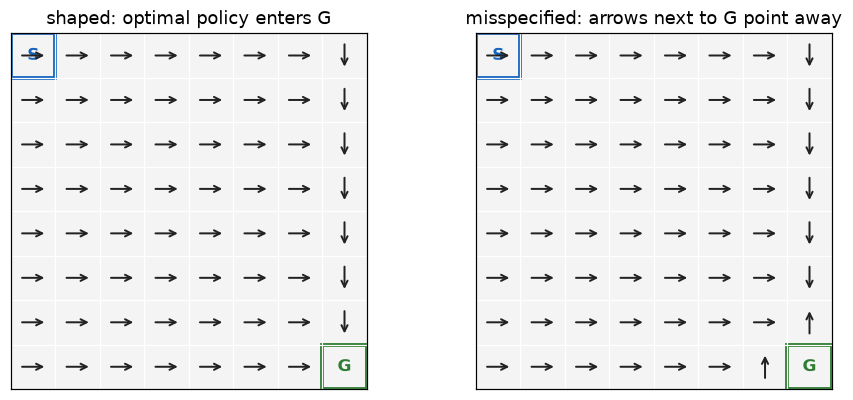

In [9]:
hacked = GridWorld(size=8, reward_mode="misspecified", gamma=GAMMA)
shaped = GridWorld(size=8, reward_mode="shaped", gamma=GAMMA)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
grid_figure(shaped, axs[0], policy=shaped.optimal_policy(GAMMA), title="shaped: optimal policy enters G")
grid_figure(hacked, axs[1], policy=hacked.optimal_policy(GAMMA), title="misspecified: arrows next to G point away")
plt.show()

## 6. SARSA against Q-learning on the cliff

SARSA ([`algos/sarsa.py:75-77`](../algos/sarsa.py)) changes one term of the target: $Q(s', a')$ for the action it **will** take, instead of $\max_{a'} Q(s', a')$.
So SARSA learns the value of the epsilon-greedy policy it follows. Q-learning learns the value of the greedy policy it does not follow.

**CliffWalking** (Sutton & Barto, Example 6.6): a 4×12 grid. Start `S` bottom left, goal `G` bottom right, a cliff `C` between them.
Each step costs −1. Stepping into the cliff costs −100 and returns the agent to the start.

Two exact numbers per method:
- **greedy**: the return of $\arg\max Q$, the policy the method claims is best
- **as followed**: the return of the ε-greedy policy it actually runs while training

Same α = 0.2, ε = 0.1, 30,000 steps, 5 seeds ([`experiments/cliff_sarsa_vs_qlearning.py`](../experiments/cliff_sarsa_vs_qlearning.py)).

exact optimum -12.248

     method  greedy (median)  as followed (median)    path steps per seed
 Q-learning          -12.248               -46.607   [13, 13, 13, 13, 13]
      SARSA          -15.706               -20.452   [17, 17, 17, 17, 17]


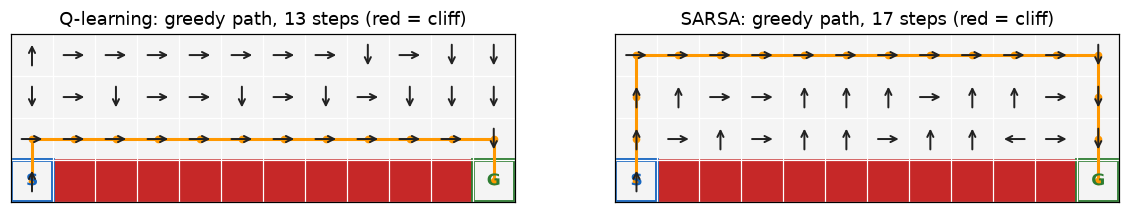

In [10]:
from algos import sarsa
from envs import solvers
from envs.cliff import CliffWalking

cliff = CliffWalking()
CG = 0.99

res = {}
for name, method in (("Q-learning", q_learning), ("SARSA", sarsa)):
    rows = []
    for seed in range(5):
        Q, _ = method.train(cliff, gamma=CG, alpha=0.2, epsilon=0.1, n_steps=30_000, eval_every=30_000, seed=seed)
        rows.append((Q, cliff.policy_return(Q.argmax(1), CG),
                     cliff.policy_return(solvers.epsilon_greedy_policy(Q, 0.1), CG), len(sarsa.greedy_path(cliff, Q)) - 1))
    res[name] = rows

print(f"exact optimum {cliff.optimal_return(CG):.3f}\n")
print(f"{'method':>11} {'greedy (median)':>16} {'as followed (median)':>21} {'path steps per seed':>22}")
for name, rows in res.items():
    print(f"{name:>11} {np.median([r[1] for r in rows]):>16.3f} {np.median([r[2] for r in rows]):>21.3f} "
          f"{str([r[3] for r in rows]):>22}")

fig, axs = plt.subplots(1, 2, figsize=(13, 2.8))
for ax, (name, rows) in zip(axs, res.items()):
    path = sarsa.greedy_path(cliff, rows[0][0])
    grid_figure(cliff, ax, policy=rows[0][0], path=path, title=f"{name}: greedy path, {len(path) - 1} steps (red = cliff)")
plt.show()

Q-learning wins the **greedy** column and loses the **as followed** column. SARSA does the opposite. Neither is wrong: they value different policies.

One thing the table hides: SARSA needs a smaller step size. Its target contains a random action, so at α = 0.5 (Q-learning's default) and 30,000 steps its greedy policy loops forever on 2 of 5 seeds.
That measurement is recorded at the top of [`algos/sarsa.py`](../algos/sarsa.py).

## 7. Dyna-Q: planning with a learned model

Q-learning uses each real transition once. Dyna-Q ([`algos/dyna_q.py`](../algos/dyna_q.py), Sutton 1990, [PDF](../papers/tabular/sutton-1990-dyna.pdf)) also stores it, model[s, a] = (r, s′),
and after every real step replays n remembered transitions through the same update. Real experience is expensive; replaying memory is cheap.
A 10×10 sparse grid with a wall, 3 seeds per setting; the metric is real environment steps until the greedy policy is exactly optimal.

 planning steps    real steps to optimal, per seed


              0               [6800, 10600, 10300]


              5                 [1200, 1700, 2600]


             50                  [1500, 1000, 900]


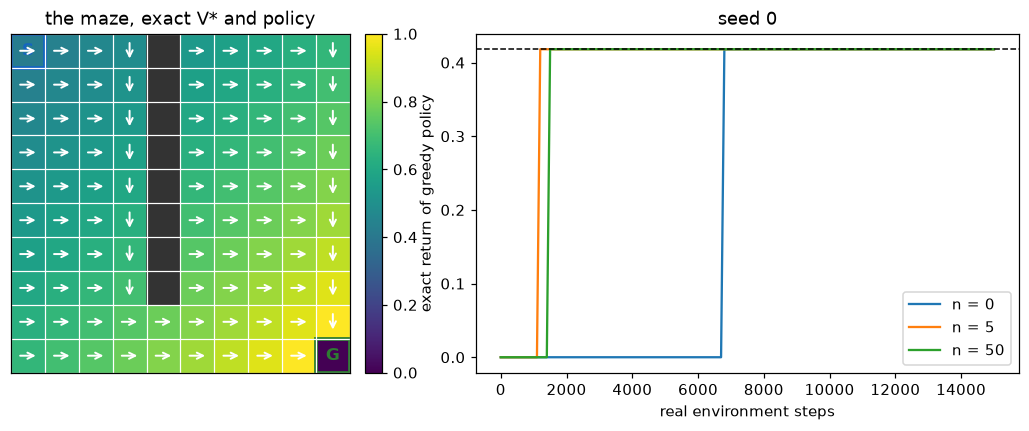

In [11]:
from algos import dyna_q

maze = GridWorld(size=10, reward_mode="sparse", walls=[(r, 4) for r in range(0, 8)], max_steps=300)
maze_optimal = maze.optimal_return(dyna_q.GAMMA)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1, 1.4]))
grid_figure(maze, axs[0], values=maze.true_v(dyna_q.GAMMA), policy=maze.optimal_policy(dyna_q.GAMMA), title="the maze, exact V* and policy")
print(f"{'planning steps':>15} {'real steps to optimal, per seed':>34}")
for n in (0, 5, 50):
    hits = []
    for seed in range(3):
        _, curve = dyna_q.train(maze, n_steps=15_000, planning_steps=n, seed=seed)
        hits.append(next((s for s, v in curve if v >= maze_optimal - 1e-6), None))
        if seed == 0:
            axs[1].plot(*zip(*curve), label=f"n = {n}")
    print(f"{n:>15} {str(hits):>34}")
axs[1].axhline(maze_optimal, color="k", ls="--", lw=1); axs[1].set_xlabel("real environment steps")
axs[1].set_ylabel("exact return of greedy policy"); axs[1].set_title("seed 0"); axs[1].legend()
plt.show()

Measured over 5 seeds by `python algos/dyna_q.py`: median 9,300 real steps with no planning, 1,800 with 5 planning steps, 1,000 with 50.
The model here keeps only the last outcome per (s, a), which is exact on this deterministic grid and would be wrong on a stochastic one.

## 8. What breaks, and how you would know

From the bottom of [`algos/q_learning.py`](../algos/q_learning.py):

| symptom | cause |
| --- | --- |
| return climbs then collapses | `alpha` too high; one unlucky target overwrites a good estimate |
| return flat at 0 on a sparse reward | the goal was never reached; print the goal's visit count before tuning anything |
| curve looks fine, policy is wrong | compare against `env.true_q(gamma)` cell by cell (section 4) |
| Q values grow without bound | terminal mask missing, or `gamma = 1` on a task that need not end |
| training return worse than SARSA's | expected: Q-learning learns the optimal policy and behaves worse while exploring |

**Next:** [`imitation_01_bc_dagger_irl_gail.ipynb`](imitation_01_bc_dagger_irl_gail.ipynb), same exact-evaluation idea on a 7,126-state racetrack.